In [40]:
# 1. 수집
# 2. 탐색
# 2-1) 데이터를 읽고 구조 확인 자료형

In [41]:
import koreanize_matplotlib     #차트 한글 깨짐 방지
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
# pandas, seaborn 라이브러리 사용 옵션 설정
pd.set_option("display.max_columns", 100) #  최대 100개 열까지 표시한다.
pd.set_option("display.max_rows", 100) # 최대 100개 행까지 표시한다.
pd.set_option("display.width", 140) # 표의 출력 너비를 140자로 설정해 줄바꿈을 줄인다.
# seaborn 그래프의 기본 모양을 흰 배경과 격자선으로 설정하고, 노트북에 맞는 글자·요소 크기를 사용한다.
sns.set_theme(style="whitegrid", context="notebook") 

In [43]:
df= pd.read_csv("train.csv")
df.head(3).T        # T = 열검색

,0,1,2
Id,1,2,3
MSSubClass,60,20,60
MSZoning,RL,RL,RL
LotFrontage,65.0,80.0,68.0
LotArea,8450,9600,11250
Street,Pave,Pave,Pave
Alley,NaN,NaN,NaN
LotShape,Reg,Reg,IR1
LandContour,Lvl,Lvl,Lvl
Utilities,AllPub,AllPub,AllPub


In [44]:
# 행 중복확인
df.duplicated().sum()     # axis = 0 기본값 -> 행 -> 이전에 동일한 행이 존재하면 True 아니면 False -> sum() 집계하면 True의 갯수

np.int64(0)

In [45]:
# 컬럼(열)의 이름만 중복확인
df.columns.duplicated().sum()

np.int64(0)

In [46]:
#자료형
df.info()
df.dtypes.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

str        43
int64      35
float64     3
Name: count, dtype: int64

In [47]:
#df.loc[조건,[열이름]]
df.loc[df["PoolQC"].isna(),["PoolQC","PoolArea"]]
df.loc[df["PoolQC"].notna(),["PoolQC","PoolArea"]]

,PoolQC,PoolArea
197,Ex,512
810,Fa,648
1170,Gd,576
1182,Ex,555
1298,Gd,480
1386,Fa,519
1423,Gd,738


In [48]:
# 변수 탐색 + 품질검사(논리 검증)

In [49]:
# 고유값 확인

# df[컬럼].nunique() 값

#df["1stFlrSF"].nunique()    # unique 값이 753 -> 범주형 X
#df["PoolQC"].nunique(dropna= False)    # unique 값이 4 -> 범주형 가능성 多 / dropna= False NaN 포함

# for c in df.columns:
#     print(c,df[c].nunique()) 

# for 반복문
# t1=[]
# for c in df.columns:
#     t1.append(df[c].nunique(dropna=False))
# t1

# 컴프리헨션
t1 = [df[c].nunique(dropna=False) for c in df.columns]
t1

[1460,
 15,
 5,
 111,
 1073,
 2,
 3,
 4,
 4,
 2,
 5,
 3,
 25,
 9,
 8,
 5,
 8,
 10,
 9,
 112,
 61,
 6,
 8,
 15,
 16,
 4,
 328,
 4,
 5,
 6,
 5,
 5,
 5,
 7,
 637,
 7,
 144,
 780,
 721,
 6,
 5,
 2,
 6,
 753,
 417,
 24,
 861,
 4,
 3,
 4,
 3,
 8,
 4,
 4,
 12,
 7,
 4,
 6,
 7,
 98,
 4,
 5,
 441,
 6,
 6,
 3,
 274,
 202,
 120,
 20,
 76,
 8,
 4,
 5,
 5,
 21,
 12,
 5,
 9,
 6,
 663]

In [50]:
# 고유값 품질 요약
unque_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.values,
    "nunique(na)": [df[c].nunique(dropna=False) for c in df.columns],   #t1
    "nunique(ratio)" : [df[c].nunique(dropna=False)/len(df) for c in df.columns]
})
unque_summary

,column,dtype,nunique(na),nunique(ratio)
0,Id,int64,1460,1.000000
1,MSSubClass,int64,15,0.010274
2,MSZoning,str,5,0.003425
3,LotFrontage,float64,111,0.076027
4,LotArea,int64,1073,0.734932
5,Street,str,2,0.001370
6,Alley,str,3,0.002055
7,LotShape,str,4,0.002740
8,LandContour,str,4,0.002740
9,Utilities,str,2,0.001370


In [51]:
# 개별변수의 고유값을 상세히 탐색

df["Street"].value_counts()
df["PoolQC"].value_counts(dropna = False)

# 타입이 숫자인 컬럼별 값별 갯수
for nc in df.select_dtypes("number"):
    display(df[nc].value_counts(dropna=False))

Id
1       1
2       1
3       1
4       1
5       1
       ..
1456    1
1457    1
1458    1
1459    1
1460    1
Name: count, Length: 1460, dtype: int64

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

LotFrontage
NaN      259
60.0     143
70.0      70
80.0      69
50.0      57
        ... 
138.0      1
160.0      1
152.0      1
153.0      1
46.0       1
Name: count, Length: 111, dtype: int64

LotArea
7200     25
9600     24
6000     17
10800    14
9000     14
         ..
26142     1
9262      1
17217     1
13175     1
9717      1
Name: count, Length: 1073, dtype: int64

OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     18
2       3
1       2
Name: count, dtype: int64

OverallCond
5    821
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64

... (28 outputs left out)

MiscVal
0        1408
400        11
500         8
700         5
450         4
2000        4
600         4
480         2
1200        2
350         1
15500       1
800         1
3500        1
1300        1
54          1
620         1
560         1
1400        1
8300        1
1150        1
2500        1
Name: count, dtype: int64

MoSold
6     253
7     234
5     204
4     141
8     122
3     106
10     89
11     79
9      63
12     59
1      58
2      52
Name: count, dtype: int64

YrSold
2009    338
2007    329
2006    314
2008    304
2010    175
Name: count, dtype: int64

SalePrice
140000    20
135000    17
145000    14
155000    14
110000    13
          ..
92000      1
287090     1
266500     1
142125     1
147500     1
Name: count, Length: 663, dtype: int64

In [52]:
# 타입이 object인 컬럼별 값별 갯수
# for oc in df.select_dtypes("object"):
#     display(df[oc].value_counts(dropna=False))

for oc in df.select_dtypes("object"):
    print(len(df[oc].value_counts(dropna=False)))

5
2
3
4
4
2
5
3
25
9
8
5
8
6
8
15
16
4
4
5
6
5
5
5
7
7
6
5
2
6
4
7
6
7
4
6
6
3
4
5
5
9
6


C:\Users\user\AppData\Local\Temp\ipykernel_14164\427240772.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for oc in df.select_dtypes("object"):


In [53]:
# 결측치 품질 요약
# 탐색 확인이 목적 -> 대체 / 다른 값으로 기록

na_summary = pd.DataFrame({
    "column":df.columns,
    "dtype":df.dtypes.values,
    "na(count)":df.isna().sum()
}).sort_values("na(count)",ascending=False)     #Nan갯수 크기 기준 나열

na_summary

# Nan 값이 1000개 이상(PoolQC,MiscFeature,.....)일 경우 변수 제거 고려

# PoolQC	PoolQC	str	1453
# MiscFeature	MiscFeature	str	1406
# Alley	Alley	str	1369
# Fence	Fence	str	1179
# MasVnrType	MasVnrType	str	872
# FireplaceQu	FireplaceQu	str	690
# LotFrontage	LotFrontage	float64	259
# GarageQual	GarageQual	str	81
# GarageFinish	GarageFinish	str	81
# GarageType	GarageType	str	81
# GarageYrBlt	GarageYrBlt	float64	81
# GarageCond	GarageCond	str	81

,column,dtype,na(count)
PoolQC,PoolQC,str,1453
MiscFeature,MiscFeature,str,1406
Alley,Alley,str,1369
Fence,Fence,str,1179
MasVnrType,MasVnrType,str,872
FireplaceQu,FireplaceQu,str,690
LotFrontage,LotFrontage,float64,259
GarageQual,GarageQual,str,81
GarageFinish,GarageFinish,str,81
GarageType,GarageType,str,81


In [54]:
# 다른 형태의 품질 요약
# 품질검사 -> 논리검정 -> 논리에 반하는 데이터가 있다(탐색) -> 삭제 및 대체는 전처리 단계에서

# SalePrice < 0 
# YearBuilt > YearRemodAdd

df.loc[df["YearBuilt"] > df["YearRemodAdd"]]  # 결측치 없음

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [55]:
df.loc[df["SalePrice"] < 0]   # 결측치 없음

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [56]:
df.loc[df["YearBuilt"] > df["YrSold"]]    # 결측치 없음

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [57]:
# 수치형 기술 통계량 점검
df.describe().T         # T 열과 행 위치변경
df.describe(include="object").T
df.describe(include="number").T

C:\Users\user\AppData\Local\Temp\ipykernel_14164\1463150349.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


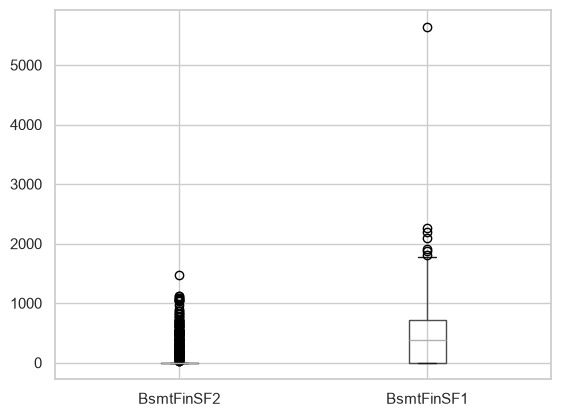

In [58]:
# 수치형 분포도(?) 확인
df.boxplot(["BsmtFinSF2","BsmtFinSF1"])
plt.show()

In [59]:
#　결측치 예상 데이터 확인
df[df["BsmtFinSF1"]>5600].T

,1298
Id,1299
MSSubClass,60
MSZoning,RL
LotFrontage,313.0
LotArea,63887
Street,Pave
Alley,NaN
LotShape,IR3
LandContour,Bnk
Utilities,AllPub


In [60]:
# 변수값 논리검정

# 예시1) 가격·면적의 음수 여부: SalePrice, LotArea, GrLivArea가 0보다 작은 행을 찾는다.

# 예시2) 연도 관계: YearBuilt가 YrSold보다 큰 집을 찾는다. 리모델링 연도(YearRemodAdd)가 판매 연도보다 늦은지도 확인한다.


In [ ]:
# 예시6) 식별자 중복: Id가 중복되거나 비어 있는지 확인한다.

#전체 1460개 고유값 1460 -> 식별자 검정
#RDB의 PK 검증

#결측치 확인
print(df["Id"].isna().sum()) # 0-> 식별자 결측치가 없다
# 중복값 여부확인
print(df["Id"].duplicated().sum())   
# 위에서 하나라도 1이 있다면 조건식으로 행을 탐색
df[(df["Id"].isna() == True) | (df["Id"].duplicated() == True)]

0
0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [62]:
# 예시5) 월 범위: MoSold가 1~12 범위인지 확인한다.


df["MoSold"].value_counts()
df["MoSold"].unique()

array([ 2,  5,  9, 12, 10,  8, 11,  4,  1,  7,  3,  6])

In [63]:
# MoSold의 결측치 확인

df[(df["MoSold"]<1) |(df["MoSold"]>12)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [64]:
# 예시4) 방·욕실 수: BedroomAbvGr, FullBath, GarageCars 등에 음수나 비현실적인 값이 있는지 확인한다.

df[(df["BedroomAbvGr"]<0)|(df["FullBath"]<0)|(df["GarageCars"]<0)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [ ]:
# 예시3) 면적 합계: GrLivArea가 1stFlrSF + 2ndFlrSF + LowQualFinSF와 맞는지 확인한다.

df[["1stFlrSF","2ndFlrSF","LowQualFinSF"]]

df[df["GrLivArea"] != (df["1stFlrSF"]+df["2ndFlrSF"]+df["LowQualFinSF"])]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
